# Save several routes in one GeoJSON file

[GeoJSON](https://geojson.org) is a common file format for geographic data. Most map tools read it, for example QGIS, kepler.gl or [geojson.io](https://geojson.io).

This notebook computes three sea routes from Baltimore to ports of Europe. It saves them in one GeoJSON file with `get_multi_path_geojson`, then reads the file and draws its routes on a map.

You need scgraph, and [cartopy](https://scitools.org.uk/cartopy/) with [matplotlib](https://matplotlib.org) for the map. The notebook downloads the sea network `world_sea` once (3.7 MB). It then runs in a few seconds.

In [1]:
# Until scgraph 4.0 is on PyPI, install it from the `dev` branch:
# %pip install "scgraph @ git+https://github.com/connor-makowski/scgraph@dev" cartopy matplotlib
import json

import cartopy.crs as ccrs
import cartopy.feature
import matplotlib.pyplot as plt

from scgraph import GeoGraph

## 1. Describe the routes

`world_sea` holds the sea lanes and the ports of the world.

Each route is a dictionary with four keys:

- `origin` and `destination`: two places, each with a latitude and a longitude.
- `geograph`: the network to route on. Each route can use another network.
- `properties`: any data to keep with the route in the file. Here, a name and a color for the map.

In [2]:
world_sea = GeoGraph.load_geograph("world_sea")

BALTIMORE = {"latitude": 39.2904, "longitude": -76.6122}
PORTS = {
    "Rotterdam": ({"latitude": 51.95, "longitude": 4.14}, "#2a78d6"),
    "Hamburg": ({"latitude": 53.54, "longitude": 9.98}, "#eb6834"),
    "Le Havre": ({"latitude": 49.48, "longitude": 0.11}, "#1baf7a"),
}

routes = [
    {
        "origin": BALTIMORE,
        "destination": place,
        "geograph": world_sea,
        "properties": {"name": f"Baltimore to {port}", "color": color},
    }
    for port, (place, color) in PORTS.items()
]

## 2. Compute the routes and save the file

`get_multi_path_geojson` computes the shortest path of each route. It returns the GeoJSON content as a dictionary. With `filename`, it also writes the file, here in the current folder.

The file holds one **feature** for each route. The geometry of a feature is a line, given as a list of points. A GeoJSON point is `[longitude, latitude]`, in this order.

In [3]:
geojson = GeoGraph.get_multi_path_geojson(routes, filename="baltimore_to_europe.geojson")

for feature in geojson["features"]:
    geometry = feature["geometry"]
    print(f"{feature['properties']['name']:<24}{geometry['type']} of {len(geometry['coordinates'])} points")

with open("baltimore_to_europe.geojson") as file:
    print(f"The file holds {len(json.load(file)['features'])} features.")

Baltimore to Rotterdam  LineString of 382 points
Baltimore to Hamburg    LineString of 348 points
Baltimore to Le Havre   LineString of 332 points
The file holds 3 features.


## 3. Draw the file on a map

The function `draw_map` draws lines and places on a map, with [cartopy](https://scitools.org.uk/cartopy/). The next cell reads the file again. It turns each GeoJSON point `[longitude, latitude]` back into `[latitude, longitude]`, and draws each line with the color of its `properties`.

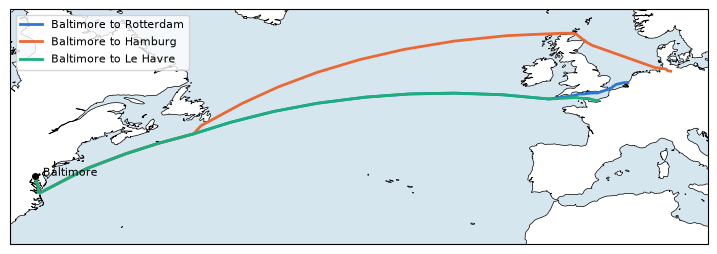

In [4]:
def draw_map(lines, places=(), extent=None, central_longitude=0, title=None, coasts="50m"):
    """A static map of lines and places, as a matplotlib figure.

    `lines` is a list of (points, color, label), with the points of a line as
    [latitude, longitude]. `places` is a list of (point, name). `extent` is
    [west, east, south, north] in degrees, or None for the whole world.
    `central_longitude` is the longitude in the middle of the map. `coasts` is
    the scale of the coasts: "110m" keeps a map of the whole world light.
    """
    figure = plt.figure(figsize=(9, 4.5))
    ax = figure.add_subplot(projection=ccrs.PlateCarree(central_longitude=central_longitude))
    if extent is None:
        ax.set_global()
    else:
        ax.set_extent(extent, crs=ccrs.PlateCarree())
    # The map fills the ocean, not the land: the land fill of cartopy fails on some regional maps
    ax.add_feature(cartopy.feature.OCEAN.with_scale(coasts), facecolor="#d6e6ef")
    ax.coastlines(coasts, linewidth=0.5)
    for points, color, label in lines:
        latitudes, longitudes = zip(*points)
        # Geodetic draws each step as a great circle, the line along which scgraph measures
        # lengths. It also cuts a line where the line crosses the edge of the map.
        ax.plot(longitudes, latitudes, color=color, linewidth=2, label=label, transform=ccrs.Geodetic())
    for (latitude, longitude), name in places:
        ax.plot(longitude, latitude, "ko", markersize=4, transform=ccrs.PlateCarree())
        ax.text(longitude, latitude, f"  {name}", fontsize=8, transform=ccrs.PlateCarree())
    if any(label for _, _, label in lines):
        ax.legend(loc="best", fontsize=8)
    ax.set_title(title)
    return figure


with open("baltimore_to_europe.geojson") as file:
    features = json.load(file)["features"]

figure = draw_map(
    lines=[
        (
            [[latitude, longitude] for longitude, latitude in feature["geometry"]["coordinates"]],
            feature["properties"]["color"],
            feature["properties"]["name"],
        )
        for feature in features
    ],
    places=[([39.2904, -76.6122], "Baltimore")],
    extent=[-80, 15, 30, 62],
)
plt.show()

The routes to Rotterdam and to Le Havre share their path until the entrance of the English Channel. The route to Hamburg leaves them in the middle of the Atlantic Ocean. It passes north of Scotland, then crosses the North Sea.

The file does not hold the lengths of the routes. To get a length, call `get_shortest_path` for the route: it returns the `length` with the path.